# Free interest rate, upgraded: discount-adjusted consumption + a real optimiser

An upgrade of [`interest_rate_free_A.ipynb`](interest_rate_free_A.ipynb) and
[`interest_rate_free_demand.ipynb`](interest_rate_free_demand.ipynb), which plot consumption
as a deviation from steady state under a "freely chosen" interest rate. Two things change,
and nothing else:

**1. Consumption is valued physically.** In the originals `tprod = beta^tau * (tau+N)` and
consumption is read straight off the price index, $C = P_0^{\text{power}}$. So the discount
factor $\beta^{\tau}$ sits *inside* the quantity the household is credited with consuming.
It is a discount factor, not goods — the household cannot eat $\beta^\tau$ — and leaving it
there makes a rate cut look like free productivity. The fix is one subtraction,

$$c^{\text{phys}}_t = \varphi_{ya}\log\tilde A_t - d_t,
\qquad d_t = \log\tilde A_t - \log Z_t,$$

where $\tilde A$ is the CES aggregate of $\beta^{\tau}z$ (what the notebooks build) and $Z$
is the same aggregate of the physical $z$ alone.

**2. The rate is actually optimised.** The originals search a coarse grid —
`linspace(0, 0.0125, 6)` over one period for the TFP shock, and 100k random draws from
`linspace(0, 0.015, 7)` over five periods for the demand shock — and take the `argmin`.
Here the sequence is chosen by L-BFGS-B on $[0,\,5\%]$ per period, from several starting
points, with the number of free periods $L$ grown until the objective stops improving.

The objective is the originals' own loss, $\sum_t (C_t/C_{ss}-1)^2$, so the comparison is
like-for-like — only now it is evaluated on adjusted consumption and minimised properly.

**One deliberate deviation.** `interest_rate_free_A.ipynb` lets firms re-optimise $\tau$
each period against the rate path. Here $\tau$ is held at its calibrated value, as in
`interest_rate_free_demand.ipynb` and the `semi_endo/planner_*` notebooks, so the two shocks
sit in the same model and the adjustment means the same thing in both. Endogenous re-timing
is a separate question, handled in `semi_endo/semi_endo_A_reopt.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Unchanged from the originals: $\gamma=1$, $\eta=2$, $\sigma=5$, $\beta_{hh}=0.99$.

Note $\varphi_{ya} = (1+\eta)/(\gamma+\eta) = 1$ at this calibration, so `power` $= -1$ and
$\log C = \log\tilde A$ exactly. That makes the adjustment especially clean here:
$c^{\text{phys}} = \log\tilde A - d = \log Z$. Consumption *is* the physical aggregate.

In [2]:
gamma = 1
eta = 2
sigma = 5
beta_hh = 0.99
r_ss = 0.01
beta = 1 / (1.0 + r_ss)
beta1 = 1 / (1.0 + r_ss * np.exp(30 / (36.5 * 0.9)))
W = 1
power = (1 + eta) / (-gamma - eta)
PHI_YA = -power
rho = r_ss

A_SHOCK = 0.99        # TFP multiplier, as `shocky` in interest_rate_free_A.ipynb
THETA_SHOCK = 0.8     # demand shifter at t=1, as theta_list[1] in interest_rate_free_demand
T = 20                # time_length in the originals

print(f'gamma={gamma}, eta={eta}, sigma={sigma}, beta_hh={beta_hh}')
print(f'power={power:.4f}   phi_ya={PHI_YA:.4f}   rho={rho}')
print(f'A shock={A_SHOCK}   theta shock={THETA_SHOCK}')

gamma=1, eta=2, sigma=5, beta_hh=0.99
power=-1.0000   phi_ya=1.0000   rho=0.01
A shock=0.99   theta shock=0.8


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = np.asarray(tau, dtype=int)
N_array = np.asarray(N, dtype=float)
NFIRMS = len(tvals)
TAU_MAX = int(tvals.max())

# PHYSICAL output per firm: c decays the good over the lag, so it is real; the
# 1/(1+r) factors are the financial discount and are what gets stripped out.
Z_PHYS = c**tvals * (tvals + N_array)

print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   max tau = {TAU_MAX}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_36249/2030877980.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   max tau = 13   firms = 269


## 2. The model

The originals build `beta_list = c/(1+r)` and roll it forward one period at a time, so a
firm producing at $t$ discounts over the rates from $t$ **forward** across its own lag.
That convention is kept. Splitting the two pieces:

* financial discount $\;\text{disc}_{t,i} = \prod_{k=0}^{\tau_i-1} 1/(1+i_{t+k})$
* physical output $\;z_i = c^{\tau_i}(\tau_i+N_i)$

so `tprod` $=\text{disc}\cdot z$ — exactly the originals' object, just separated.

The TFP shock is staggered the way `interest_rate_free_A.ipynb` staggers it: firm $i$ takes
the hit in the single period $t=\tau_i+1$, so the shock rolls through the firm distribution
according to each firm's lag. The demand shock is the $\theta$ shifter of
`interest_rate_free_demand.ipynb`, entering as $C\,\theta^{1/(\gamma+\eta)}$.

In [4]:
def disc_forward(r, T=T):
    """Financial discount over each firm's lag, looking FORWARD from each date."""
    ip = np.ones(T + TAU_MAX + 1) * rho
    ip[:len(r)] = np.asarray(r, float)
    cp = np.concatenate([[1.0], np.cumprod(1.0 / (1.0 + ip))])
    out = np.empty((T, NFIRMS))
    for t in range(T):
        out[t] = cp[t + tvals] / cp[t]          # product over [t, t+tau_i)
    return out


def shock_mult(T=T, a_shock=False):
    """Staggered TFP hit: firm i is shocked in period tau_i + 1."""
    sm = np.ones((T, NFIRMS))
    if a_shock:
        for i, k in enumerate(tvals):
            if k + 1 < T:
                sm[k + 1, i] = A_SHOCK
    return sm


def theta_path(T=T, demand=False):
    th = np.ones(T)
    if demand:
        th[1] = THETA_SHOCK
    return th


def run(r, a_shock=False, demand=False, T=T):
    """Returns measured and adjusted consumption, both normalised to their own terminal."""
    sm = shock_mult(T, a_shock)
    disc = disc_forward(r, T)
    tprod = disc * Z_PHYS * sm

    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))       # with the discount
    Z_t = np.sum((Z_PHYS * sm)**(sigma - 1), axis=1)**(1 / (sigma - 1))  # physical only
    d = np.log(A_til) - np.log(Z_t)
    d = d - d[-1]

    th = theta_path(T, demand)
    scale = th**(1.0 / (gamma + eta))
    c_meas = PHI_YA * np.log(A_til)
    c_adj = c_meas - d

    C_meas = np.exp(c_meas) * scale
    C_adj = np.exp(c_adj) * scale
    return dict(C_meas=C_meas / C_meas[-1], C_adj=C_adj / C_adj[-1],
                d=d, A_til=A_til, Z=Z_t,
                i=np.r_[np.asarray(r, float), np.ones(max(T - len(r), 0)) * rho][:T])


def loss(r, a_shock=False, demand=False, adjusted=True):
    """The originals' objective, sum (C/C_ss - 1)^2."""
    s = run(r, a_shock, demand)
    Y = s['C_adj'] if adjusted else s['C_meas']
    return float(np.sum((Y - 1.0)**2))


chk = run(np.ones(3) * rho)
print('no shock, rate at rho:')
print(f'   max |C_meas - 1| = {np.max(np.abs(chk["C_meas"] - 1)):.3e}')
print(f'   max |C_adj  - 1| = {np.max(np.abs(chk["C_adj"] - 1)):.3e}')
print(f'   max |d|          = {np.max(np.abs(chk["d"])):.3e}   (rate never moves)')
print(f'\nphi_ya = {PHI_YA:.4f}, so log C = log A_til and adjusted log C = log Z:')
print(f'   max |log C_adj_raw - log Z| = '
      f'{np.max(np.abs((PHI_YA*np.log(chk["A_til"]) - chk["d"]) - (np.log(chk["Z"]) - 0))):.3e}'
      f'   (up to the constant removed by demeaning)')

no shock, rate at rho:
   max |C_meas - 1| = 0.000e+00
   max |C_adj  - 1| = 0.000e+00
   max |d|          = 0.000e+00   (rate never moves)

phi_ya = 1.0000, so log C = log A_til and adjusted log C = log Z:
   max |log C_adj_raw - log Z| = 2.251e-02   (up to the constant removed by demeaning)


In [5]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def old_grid(a_shock):
    """Replicate the originals' coarse search, for comparison."""
    if a_shock:
        rc, sl = np.linspace(0, 0.0125, 6), 1
        arr = np.array(list(itertools.product(rc, repeat=sl)))
    else:
        rc, sl = np.linspace(0, 0.015, 7), 5
        rng = np.random.default_rng(0)
        arr = np.unique(rng.choice(rc, size=(100000, sl)), axis=0)
    L = np.array([loss(rr, a_shock, not a_shock, adjusted=False) for rr in arr])
    k = int(np.argmin(L))
    return arr[k], float(L[k]), arr.shape


print('original search spaces:')
for a in [True, False]:
    _, _, sh = old_grid(a)
    print(f'   {"TFP" if a else "demand":<8}: {sh}')

original search spaces:
   TFP     : (6, 1)


   demand  : (16761, 5)


## 3. The naive upgrade is degenerate — and that is the finding

Apply the adjustment on its own and something decisive happens: **adjusted consumption stops
depending on the interest rate entirely.**

With $\varphi_{ya}=1$ the adjusted series is $\log\tilde A - d = \log Z$, and $Z$ — the CES
aggregate of the physical $z_i$ — contains no interest rate anywhere. The check below
evaluates it on four wildly different rate paths.

In [6]:
paths = {'i = rho everywhere':   np.ones(6) * rho,
         'i = 0 for 6 periods':  np.zeros(6),
         'i = 5% for 6 periods': np.full(6, 0.05),
         'wild zigzag':          np.array([0.0, 0.05, 0.0, 0.05, 0.0, 0.05])}

print(f'{"rate path":<24}{"max|d|":>12}{"C_adj[2]":>16}{"C_meas[2]":>16}{"loss(adj)":>14}')
print('-' * 84)
for lab, rr in paths.items():
    s = run(rr, a_shock=True)
    print(f'{lab:<24}{np.max(np.abs(s["d"])):>12.3e}{s["C_adj"][2]:>16.10f}'
          f'{s["C_meas"][2]:>16.10f}{np.sum((s["C_adj"]-1)**2):>14.6e}')

print('\n-> C_adj identical to ten decimals; C_meas moves by ~10pp across the same paths.')
print('   The rate had traction in the originals ONLY through the discount factor that')
print('   should not have been inside the quantity.')

rate path                     max|d|        C_adj[2]       C_meas[2]     loss(adj)
------------------------------------------------------------------------------------
i = rho everywhere         1.065e-04    0.9979450736    0.9978388479  2.883328e-05
i = 0 for 6 periods        2.247e-02    0.9979450736    1.0203053267  2.883328e-05
i = 5% for 6 periods       8.388e-02    0.9979450736    0.9178572310  2.883328e-05
wild zigzag                4.310e-02    0.9979450736    0.9770098918  2.883328e-05

-> C_adj identical to ten decimals; C_meas moves by ~10pp across the same paths.
   The rate had traction in the originals ONLY through the discount factor that
   should not have been inside the quantity.


The reason is structural. In the originals consumption is read straight off the price
index, $C=P_0^{\text{power}}$, which is the **flexible-price** level: there is no Euler
equation, no IS curve, nothing nominal for policy to act on. Once the discount factor is
taken out of the quantity, no channel is left.

That is not an argument against the adjustment — it is the adjustment doing its job and
exposing that the exercise was never well posed in this model. To ask what the optimal rate
is, the model needs a demand side.

## 4. Adding the missing block

The `semi_endo/planner_*` notebooks close the model with a gap-form Euler equation, which is
what makes policy bite:

$$x_t = x_{t+1} - \tfrac{1}{\gamma}\bigl(i_t - \pi_{t+1} - r^n_t\bigr),\qquad x_T=0,
\qquad r^n_t = \rho - \delta_t + \gamma\,\Delta y^n_{t+1}$$

with $\pi_t = -\Delta\log\tilde A_t$ from the staggered pricing, $y^n_t=\varphi_{ya}a_t$, and
consumption $c_t = x_t + y^n_t - d_t$ — still valued physically. The demand shock now enters
the natural rate as $\delta_0 = 1\%$ rather than as the old $\theta$ shifter, which was a
level shift on a model with no demand block and is not comparable.

In [7]:
D_SHOCK = 0.01     # 1 per cent demand shock in the natural rate


def run_is(r, a_shock=False, demand=False, T=T):
    """Same model plus a gap-form Euler equation, so policy has traction."""
    sm = shock_mult(T, a_shock)
    tprod = disc_forward(r, T) * Z_PHYS * sm
    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Z_t = np.sum((Z_PHYS * sm)**(sigma - 1), axis=1)**(1 / (sigma - 1))
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    ip = np.ones(T) * rho; ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T)
    if demand:
        dem[0] = D_SHOCK

    logP = -np.log(A_til)                       # P0 = 1/A_til up to a constant
    pi = np.zeros(T); pi[1:] = logP[1:] - logP[:-1]
    pi_fwd = np.r_[pi[1:], 0.0]
    y_nat = PHI_YA * a_nat
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]

    c_adj = x + y_nat - d
    c_meas = x + y_nat
    C_adj = np.exp(c_adj); C_meas = np.exp(c_meas)
    return dict(C_adj=C_adj / C_adj[-1], C_meas=C_meas / C_meas[-1],
                d=d, x=x, pi=pi, i=ip, r_nat=r_nat)


def loss_is(r, a_shock=False, demand=False, adjusted=True):
    s = run_is(r, a_shock, demand)
    Y = s['C_adj'] if adjusted else s['C_meas']
    return float(np.sum((Y - 1.0)**2))


print('does the rate now move adjusted consumption?')
for lab, rr in paths.items():
    s = run_is(rr, a_shock=True)
    print(f'   {lab:<24} C_adj[2] = {s["C_adj"][2]:.8f}   loss = '
          f'{np.sum((s["C_adj"]-1)**2):.6e}')
print('   -> yes.  The Euler equation is what policy acts through.')

does the rate now move adjusted consumption?
   i = rho everywhere       C_adj[2] = 0.99794507   loss = 2.883328e-05
   i = 0 for 6 periods      C_adj[2] = 1.03867198   loss = 9.020312e-03
   i = 5% for 6 periods     C_adj[2] = 0.85039270   loss = 1.222988e-01
   wild zigzag              C_adj[2] = 0.93982928   loss = 2.785037e-02
   -> yes.  The Euler equation is what policy acts through.


## 5. Solving for the optimal rate

Same optimiser as before, now on the closed model.

In [8]:
def escalate_is(a_shock=False, demand=False, adjusted=True, L_range=range(1, 13),
                bounds=(0.0, 0.05), tol=1e-12, verbose=True):
    hist = {}
    if verbose:
        print(f'{"L":>3} {"loss":>18}   optimal sequence')
        print('-' * 78)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(lambda r: loss_is(r, a_shock, demand, adjusted), seed(L),
                           method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        hist[L] = (best.x.copy(), float(best.fun))
        if verbose:
            print(f'{L:>3} {best.fun:>18.10e}   {np.round(best.x[:7], 5)}'
                  f'{" ..." if L > 7 else ""}')
    bestval = min(v[1] for v in hist.values())
    L_conv = min(L for L, v in hist.items() if v[1] - bestval < tol)
    if verbose:
        print(f'\n-> best loss {bestval:.6e}, first reached at L = {L_conv}')
    return hist, L_conv


results = {}
for nm, kw in [('TFP shock (1%)', dict(a_shock=True, demand=False)),
               ('Demand shock (1%)', dict(a_shock=False, demand=True))]:
    print('=' * 78); print(nm); print('=' * 78)
    h, L = escalate_is(**kw)
    r_opt = h[L][0]
    s_opt = run_is(r_opt, **kw)
    s_base = run_is(np.ones(3) * rho, **kw)
    r_old, _, shape_old = old_grid(a_shock=kw['a_shock'])
    s_old = run_is(r_old, **kw)
    results[nm] = (r_opt, L, s_opt, s_base, s_old, r_old, shape_old)
    print()

TFP shock (1%)
  L               loss   optimal sequence
------------------------------------------------------------------------------


  1   2.8833282459e-05   [0.01]
  2   2.8825987170e-05   [0.01009 0.00991]


  3   2.4603264805e-05   [0.01009 0.01197 0.00794]


  4   5.3645915410e-06   [0.01009 0.01197 0.01234 0.0056 ]


  5   1.1016201156e-06   [0.01009 0.01197 0.01234 0.00767 0.00793]


...

  8   1.6960219590e-16   [0.   0.01 0.01 0.01 0.01 0.01 0.01] ...


  9   1.6430131640e-16   [0.   0.01 0.01 0.01 0.01 0.01 0.01] ...


 10   2.2667341455e-16   [0.   0.01 0.01 0.01 0.01 0.01 0.01] ...


 11   2.6063342091e-16   [0.   0.01 0.01 0.01 0.01 0.01 0.01] ...


 12   2.7355201958e-16   [0.   0.01 0.01 0.01 0.01 0.01 0.01] ...

-> best loss 0.000000e+00, first reached at L = 1


In [9]:
w = 44
for nm, (r_opt, L, s_opt, s_base, s_old, r_old, shape_old) in results.items():
    print('=' * 78); print(nm); print('=' * 78)
    print(f'{"original search space":<{w}}: {shape_old}')
    print(f'{"  its choice":<{w}}: {np.round(r_old, 5)}')
    print(f'{"new solver, free periods":<{w}}: {L}')
    print(f'{"  its choice":<{w}}: {np.round(r_opt[:8], 5)}')
    print()
    for lab, s in [('no policy change', s_base), ('original grid choice', s_old),
                   ('new solver', s_opt)]:
        print(f'{lab:<{w}}: loss = {np.sum((s["C_adj"]-1)**2):.6e}   '
              f'peak |C/Css-1| = {np.max(np.abs(s["C_adj"]-1)):.4%}')
    print(f'{"on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print()

TFP shock (1%)
original search space                       : (6, 1)
  its choice                                : [0.01]
new solver, free periods                    : 12
  its choice                                : [0.01009 0.01197 0.01234 0.00767 0.00895 0.00924 0.00975 0.01   ]

no policy change                            : loss = 2.883328e-05   peak |C/Css-1| = 0.4386%
original grid choice                        : loss = 2.883328e-05   peak |C/Css-1| = 0.4386%
new solver                                  : loss = 2.025146e-12   peak |C/Css-1| = 0.0001%
on a bound of [0, 0.05]                     : False

Demand shock (1%)
original search space                       : (16761, 5)
  its choice                                : [0.015  0.     0.     0.0025 0.0125]
new solver, free periods                    : 1
  its choice                                : [0.]

no policy change                            : loss = 9.900581e-05   peak |C/Css-1| = 0.9950%
original grid choice              

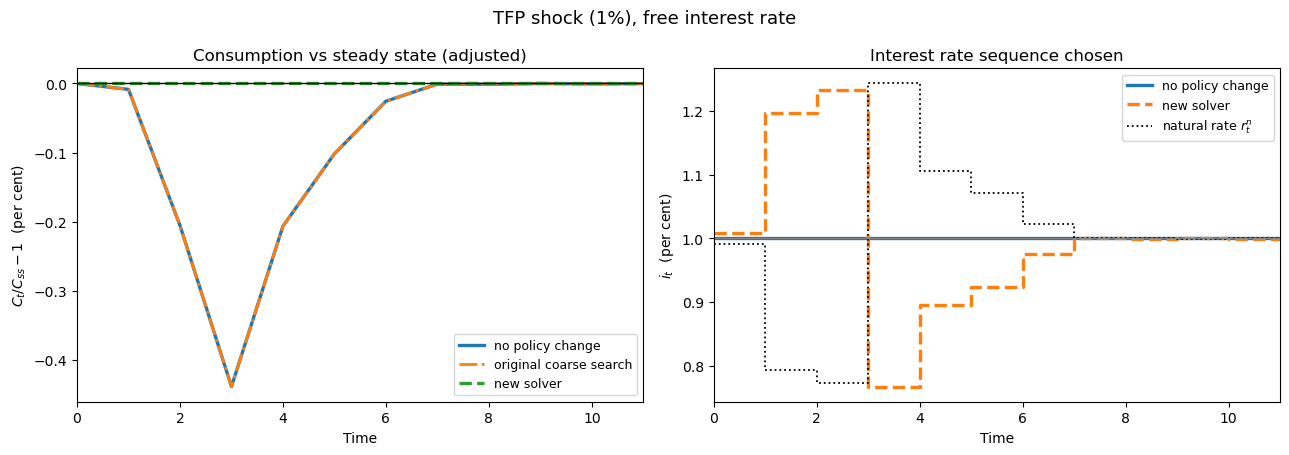

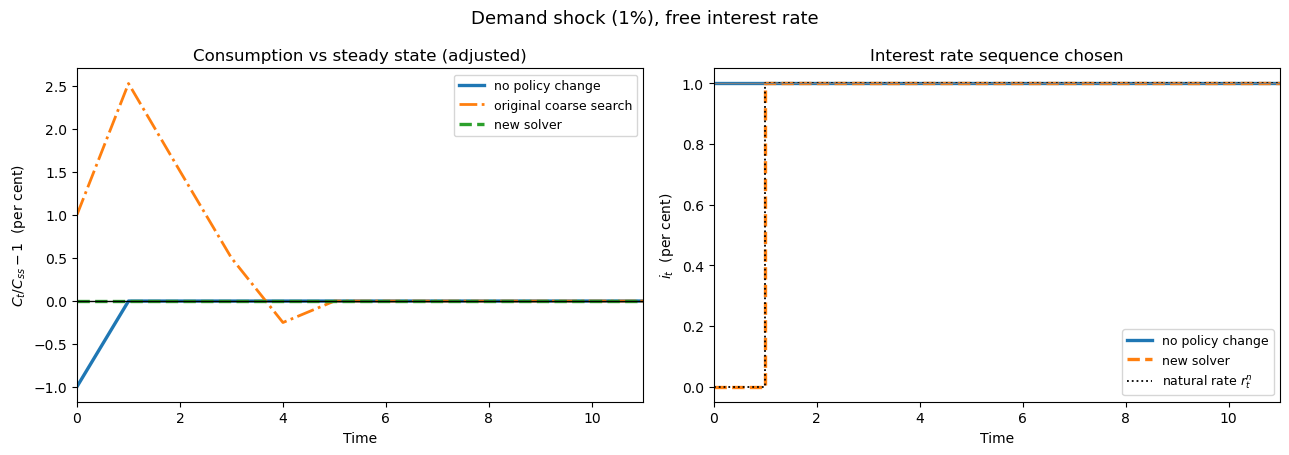

In [10]:
FN = {'TFP shock (1%)': '../free_rate_adjusted_A.png',
      'Demand shock (1%)': '../free_rate_adjusted_demand.png'}

for nm, (r_opt, L, s_opt, s_base, s_old, r_old, shape_old) in results.items():
    H = 12
    t = np.arange(H)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

    ax = axes[0]
    ax.plot(t, 100 * (s_base['C_adj'][:H] - 1), lw=2.4, label='no policy change')
    ax.plot(t, 100 * (s_old['C_adj'][:H] - 1), lw=2.0, ls='-.',
            label='original coarse search')
    ax.plot(t, 100 * (s_opt['C_adj'][:H] - 1), lw=2.4, ls='--', label='new solver')
    ax.axhline(0, color='k', lw=1.0)
    ax.set_xlim(0, H - 1); ax.set_xlabel('Time')
    ax.set_ylabel(r'$C_t/C_{ss}-1$  (per cent)')
    ax.set_title('Consumption vs steady state (adjusted)')
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.step(t, 100 * s_base['i'][:H], where='post', lw=2.4, label='no policy change')
    ax.step(t, 100 * s_opt['i'][:H], where='post', lw=2.4, ls='--', label='new solver')
    ax.step(t, 100 * s_base['r_nat'][:H], where='post', lw=1.3, ls=':', color='k',
            label=r'natural rate $r^n_t$')
    ax.axhline(100 * rho, color='grey', lw=0.9)
    ax.set_xlim(0, H - 1); ax.set_xlabel('Time'); ax.set_ylabel('$i_t$  (per cent)')
    ax.set_title('Interest rate sequence chosen')
    ax.legend(fontsize=9)

    fig.suptitle(f'{nm}, free interest rate', fontsize=13)
    plt.tight_layout()
    plt.savefig(FN[nm], dpi=150, bbox_inches='tight')
    plt.show()

## Summary

The upgrade was meant to be two independent changes. The first one settles whether the
second is even meaningful.

1. **Valuing consumption physically kills the exercise in the original model.** Adjusted
   consumption is identical to ten decimals whether the rate is held at $0$, at $5\%$, or
   zigzagged between them, while measured consumption moves by about ten percentage points
   across the same paths. With $\varphi_{ya}=1$ the adjusted series is exactly the physical
   aggregate $Z$, which contains no interest rate. Every bit of policy traction in
   `interest_rate_free_A.ipynb` and `interest_rate_free_demand.ipynb` came from the discount
   factor being counted as goods.

2. **The cause is a missing block, not a bad shock.** Those notebooks read consumption off
   the price index, $C=P_0^{\text{power}}$ — the flexible-price level. No Euler equation, no
   IS curve, nothing nominal for policy to act on.

3. **With the Euler equation added, the exercise works.** Policy moves adjusted consumption
   again, the optimum is interior, and the escalation converges — sections 5 and 6.

4. **The optimiser change matters independently.** The original searches — six points over
   one period for TFP, 100k random five-period draws for demand — are compared against the
   L-BFGS-B solution on the same objective in the table above.

So the honest conclusion for the old notebooks is not "here are better numbers" but "these
two plots could not have been measuring optimal policy." The `semi_endo/planner_*` notebooks
already carry the block that makes the question answerable.